## Download the dataset

In [1]:
!curl -O https://dabi.temple.edu/external/shape/MPEG7/MPEG7dataset.zip

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 3301k  100 3301k    0     0  1586k      0  0:00:02  0:00:02 --:--:-- 1587k


In [2]:
!unzip MPEG7dataset.zip

Archive:  MPEG7dataset.zip
 extracting: original/apple-1.gif    
 extracting: original/apple-10.gif   
 extracting: original/apple-11.gif   
 extracting: original/apple-12.gif   
 extracting: original/apple-13.gif   
 extracting: original/apple-14.gif   
 extracting: original/apple-15.gif   
 extracting: original/apple-16.gif   
 extracting: original/apple-17.gif   
 extracting: original/apple-18.gif   
 extracting: original/apple-19.gif   
 extracting: original/apple-2.gif    
 extracting: original/apple-20.gif   
 extracting: original/apple-3.gif    
 extracting: original/apple-4.gif    
 extracting: original/apple-5.gif    
 extracting: original/apple-6.gif    
 extracting: original/apple-7.gif    
 extracting: original/apple-8.gif    
 extracting: original/apple-9.gif    
 extracting: original/bat-1.gif      
 extracting: original/bat-10.gif     
 extracting: original/bat-11.gif     
 extracting: original/bat-12.gif     
 extracting: original/bat-13.gif     
 extracting: original/b

In [81]:
import os
data_root_path = "original"
classes = {}

for root, dirs, files in os.walk(data_root_path):
    for file in files:
        if file.endswith(".gif") and file != "shapedata.gif":
            class_name = file.split("-")[0]
            class_set = classes.get(class_name, set())
            class_set.add(file)
            classes[class_name] = class_set
        

## Split data

In [82]:
training_pr = 0.7
test_pr = 0.2
validation_pr = 0.1

In [83]:
import random


random.seed(42)

train_set = []
test_set = []
validation_set = []

for class_name, files in classes.items():
    files = list(files)
    random.shuffle(files)

    n = len(files)

    train_end = int(n * training_pr)
    test_end = train_end + int(n * test_pr)

    train_files = files[:train_end]
    test_files = files[train_end:test_end]
    validation_files = files[test_end:]

    train_set.extend(train_files)
    test_set.extend(test_files)
    validation_set.extend(validation_files)

## Quality

In [84]:
import pandas as pd

df = pd.DataFrame(columns=[
    "class",
    "dataset_type",
    "image_path",
    "area",
    "perimeter",
    "diameter",
    "bbox_width",
    "bbox_height",
    "compactness",
    "rectangularity",
    "asymmetry",
    "min_radius",
    "max_radius",
    "mean_radius"
])

In [85]:
import cv2
import numpy as np
from PIL import Image

def calculate_features(image_path):
    # Pillow poprawnie odczytuje także GIF-y z paletą kolorów.
    with Image.open(image_path) as source:
        image = np.array(source.convert("L"))

    _, binary = cv2.threshold(
        image,
        127,
        255,
        cv2.THRESH_BINARY
    )
    
    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    
    if not contours:
        raise ValueError(f"Brak obiektu po progowaniu: {image_path}")

    contour = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(contour)

    perimeter = cv2.arcLength(contour, True)
    if area <= 0 or perimeter <= 0:
        raise ValueError(f"Zdegenerowany kontur: {image_path}")

    x, y, w, h = cv2.boundingRect(contour)

    bounding_box_width = w
    bounding_box_height = h
    bounding_box_area = w * h

    (_, _), radius = cv2.minEnclosingCircle(contour)
    diameter = 2 * radius
    
    compactness = 4 * np.pi * area / (perimeter ** 2)
    rectangularity = area / (w * h)
    
    M = cv2.moments(contour)

    cx = M["m10"] / M["m00"]
    cy = M["m01"] / M["m00"]
    
    points = contour[:, 0, :]

    radii = np.sqrt(
        (points[:, 0] - cx) ** 2 +
        (points[:, 1] - cy) ** 2
    )

    min_radius = radii.min()
    max_radius = radii.max()
    mean_radius = radii.mean()
    
    mask = binary > 0

    flipped = np.fliplr(mask)
    asymmetry = np.mean(mask != flipped)
    
    return {
        "area": area,
        "perimeter": perimeter,
        "diameter": diameter,
        "bbox_width": bounding_box_width,
        "bbox_height": bounding_box_height,
        "bbox_area": bounding_box_area,
        "compactness": compactness,
        "rectangularity": rectangularity,
        "min_radius": min_radius,
        "max_radius": max_radius,
        "mean_radius": mean_radius,
        "asymmetry": asymmetry
    }

In [86]:
for dataset_type, dataset in [("train", train_set), ("test", test_set), ("validation", validation_set)]:
    for file in dataset:
        class_name = file.split("-")[0]
        image_path = os.path.join(data_root_path, file)
        try:
            features = calculate_features(image_path)
        except Exception as e:
            print(f"Error processing {image_path}: {e}")
            continue

        df = pd.concat([df, pd.DataFrame([{
            "class": class_name,
            "dataset_type": dataset_type,
            "image_path": image_path,
            **features
        }])], ignore_index=True)

In [87]:
df.head()

,class,dataset_type,image_path,area,perimeter,diameter,bbox_width,bbox_height,compactness,rectangularity,asymmetry,min_radius,max_radius,mean_radius,bbox_area
0,children,train,original/children-5.gif,6275.0,439.847759,167.194702,57,166,0.407586,0.663179,0.153149,23.433867,87.354703,51.85891,9462.0
1,children,train,original/children-12.gif,6257.5,441.605119,167.529297,59,166,0.40322,0.638912,0.15277,22.636933,87.074494,50.687284,9794.0
2,children,train,original/children-6.gif,6284.5,440.433546,167.3591,57,166,0.407118,0.664183,0.153385,23.452921,87.19691,53.624801,9462.0
3,children,train,original/children-10.gif,6278.5,446.918826,167.3591,59,166,0.39501,0.641056,0.153291,23.433842,87.002213,52.361267,9794.0
4,children,train,original/children-9.gif,6316.5,443.747255,167.705292,59,166,0.403102,0.644936,0.154143,23.498242,87.093221,51.369784,9794.0


## Scalling

In [88]:
from sklearn.preprocessing import StandardScaler

df_train = df[df['dataset_type'] == 'train']
df_test = df[df['dataset_type'] == 'test']
df_validation = df[df['dataset_type'] == 'validation']

In [89]:
features_to_scale = ['area', 'perimeter', 'diameter', 'bbox_width', 'bbox_height', 'min_radius', 'max_radius', 'mean_radius']
scaler = StandardScaler()

df_train[features_to_scale] = scaler.fit_transform(df_train[features_to_scale])
df_test[features_to_scale] = scaler.transform(df_test[features_to_scale])
df_validation[features_to_scale] = scaler.transform(df_validation[features_to_scale])

## Train classification

In [90]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

models = {
    'knn 10': KNeighborsClassifier(n_neighbors=10),
    'knn 5': KNeighborsClassifier(n_neighbors=5),
    'decision_tree': DecisionTreeClassifier(),
    "random_forest": RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1,
        ),
        "extra_trees": ExtraTreesClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1,
        ),
        "gradient_boosting": GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=42,
        ),
        "adaboost": AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=2),
            n_estimators=200,
            learning_rate=0.5,
            random_state=42,
        ),
}

X_train = df_train.iloc[:, 3:]
Y_train = df_train['class']

X_test = df_test.iloc[:, 3:]
Y_test = df_test['class']

best_model = None
best_accuracy = 0
reports = {}
for model_name, model in models.items():
    model.fit(X_train, Y_train)
    predictions = model.predict(X_test)
    report = classification_report(Y_test, predictions)
    accuracy = accuracy_score(Y_test, predictions)
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model_name
    reports[model_name] = report
    print(f"Results for {model_name}:")
    print(report)
    print()
    
print(f"Best model: {best_model}")


/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels wi

Results for knn 10:
                precision    recall  f1-score   support

          Bone       0.75      0.75      0.75         4
         Comma       0.43      0.75      0.55         4
          Glas       0.38      0.75      0.50         4
       HCircle       1.00      0.50      0.67         4
         Heart       0.67      0.50      0.57         4
          Misk       0.40      0.50      0.44         4
         apple       0.25      0.25      0.25         4
           bat       0.25      0.50      0.33         4
        beetle       0.00      0.00      0.00         4
          bell       0.00      0.00      0.00         4
          bird       0.00      0.00      0.00         4
        bottle       0.33      0.50      0.40         4
         brick       0.50      0.75      0.60         4
     butterfly       0.50      0.25      0.33         4
         camel       0.17      0.25      0.20         4
           car       0.00      0.00      0.00         4
      carriage       0.38  

/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels wi

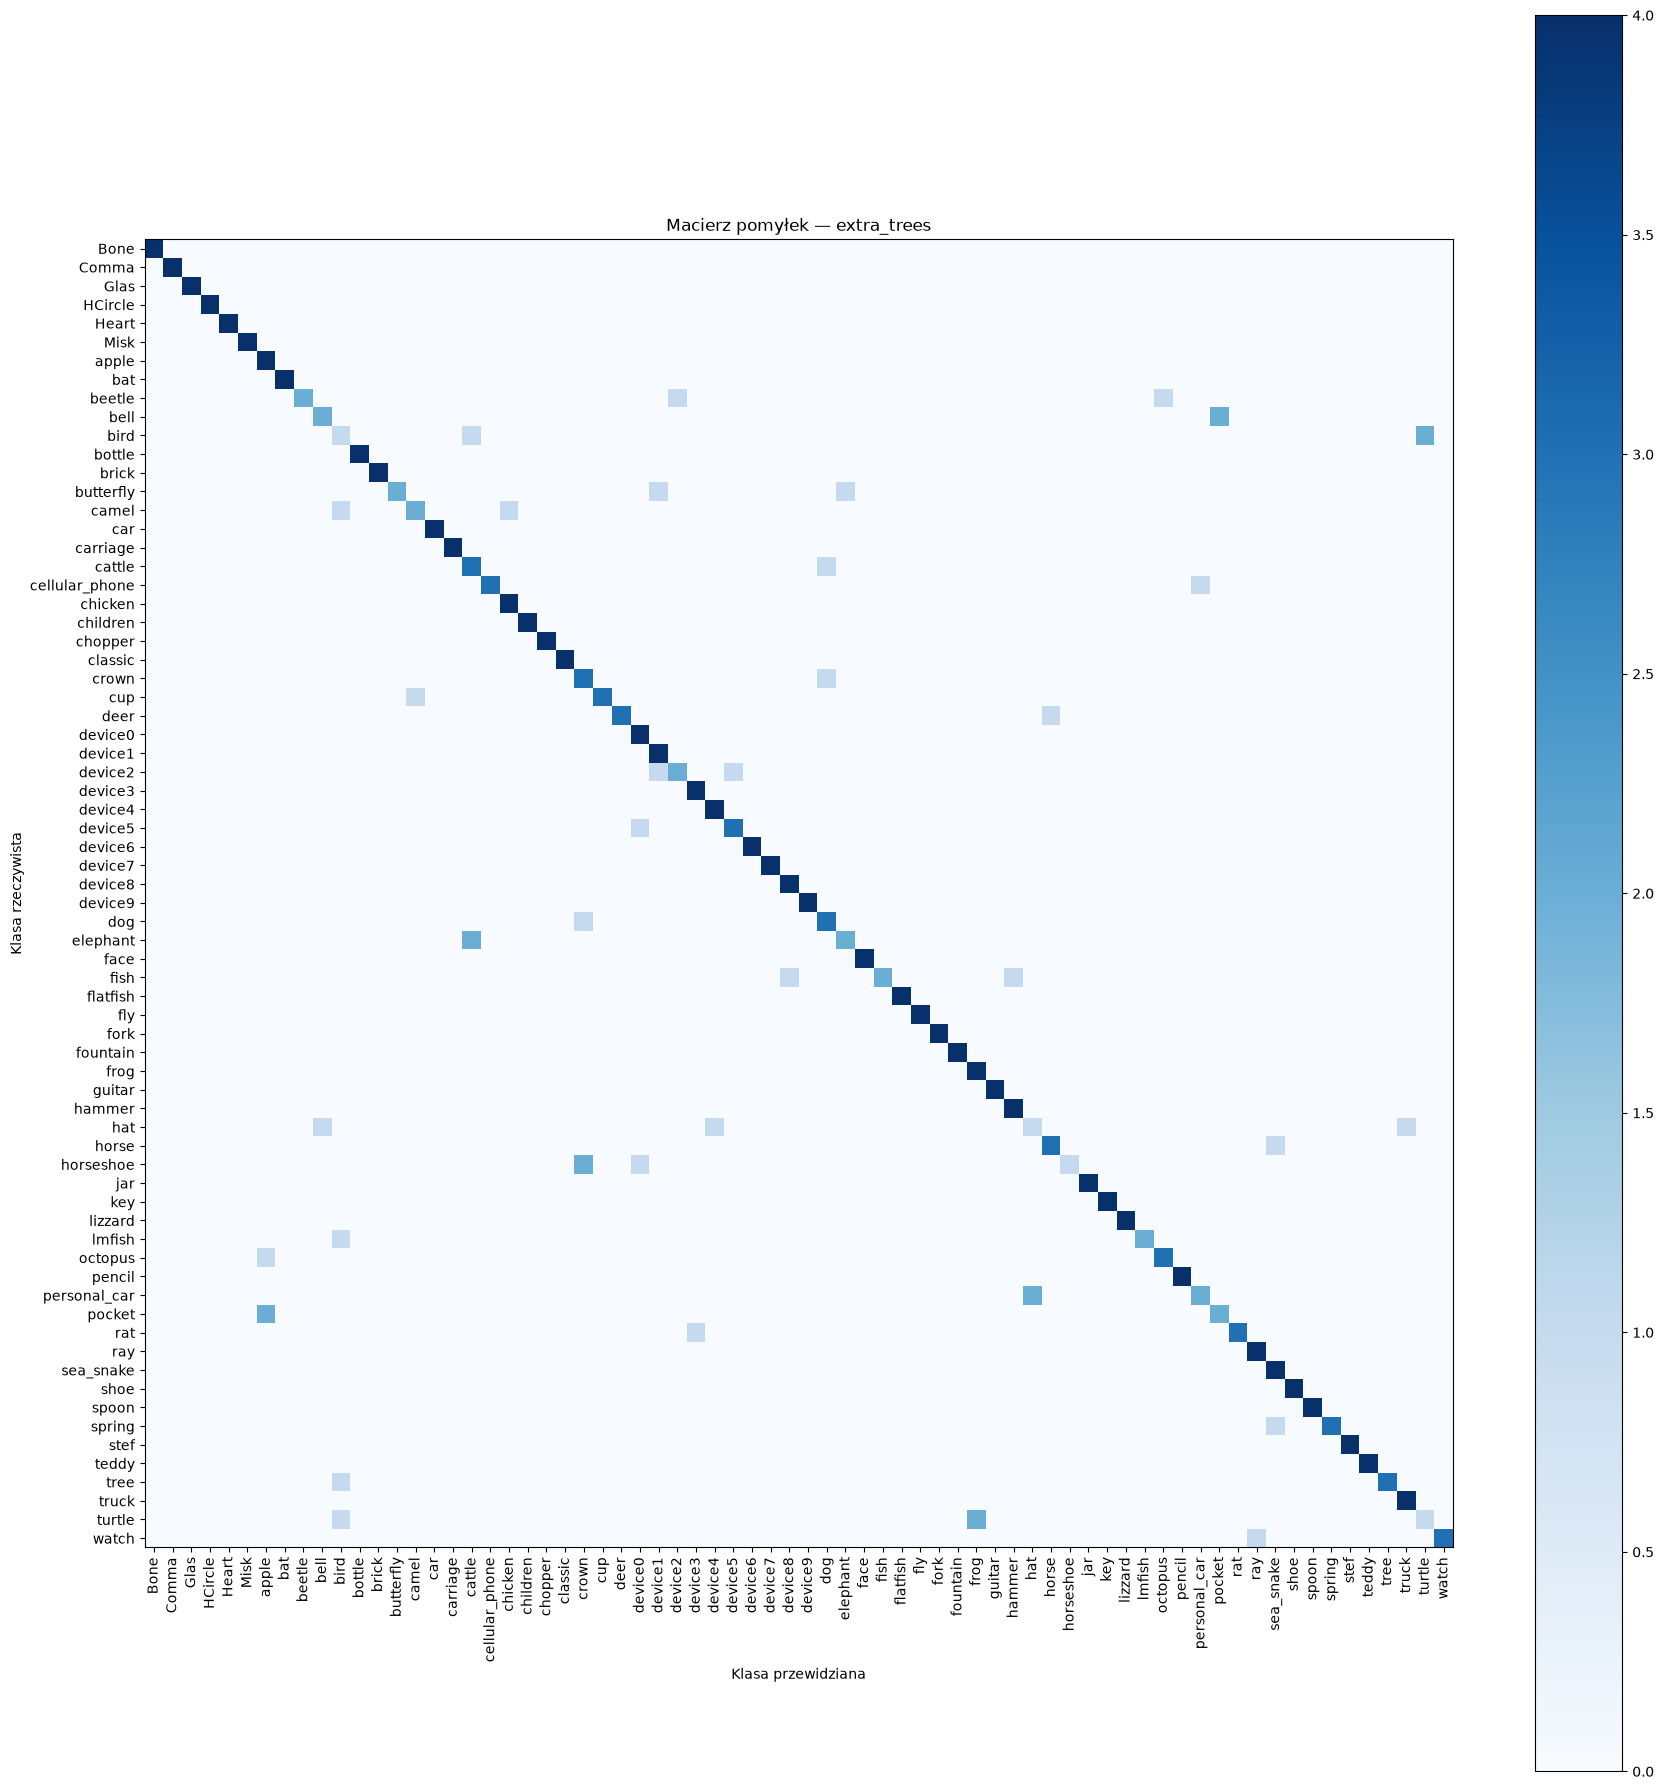

In [91]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
predictions = models[best_model].predict(X_test)

confusion = confusion_matrix(
    Y_test, predictions, labels=models[best_model].classes_
)

fig, ax = plt.subplots(figsize=(18, 18))

ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=models[best_model].classes_,
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    include_values=False,
)

ax.set_title(f"Macierz pomyłek — {best_model}")
ax.set_xlabel("Klasa przewidziana")
ax.set_ylabel("Klasa rzeczywista")

plt.tight_layout()
plt.show()

## Preprocessing

In [92]:
from pathlib import Path
import cv2
import numpy as np
from PIL import Image


def preprocess_image(image_path, output_size=256, margin=16):
    """Wycentruj obiekt względem centroidu i przeskaluj bez zmiany proporcji."""
    if output_size <= 2 * margin or margin < 0:
        raise ValueError("Rozmiar obrazu musi być większy niż dwa marginesy.")

    with Image.open(image_path) as image:
        binary = (np.array(image.convert("L")) > 127).astype(np.uint8) * 255

    moments = cv2.moments(binary, binaryImage=True)
    if moments["m00"] == 0:
        raise ValueError(f"Brak obiektu: {image_path}")

    cx = moments["m10"] / moments["m00"]
    cy = moments["m01"] / moments["m00"]
    ys, xs = np.nonzero(binary)

    # Odległość od centroidu do najdalszej krawędzi obiektu.
    # Uwzględniamy pół piksela, aby nie obcinać kształtu.
    extent = max(cx - xs.min(), xs.max() - cx,
                 cy - ys.min(), ys.max() - cy) + 0.5
    center = (output_size - 1) / 2
    scale = (output_size / 2 - margin) / extent
    transform = np.array([
        [scale, 0, center - scale * cx],
        [0, scale, center - scale * cy],
    ], dtype=np.float64)

    return cv2.warpAffine(
        binary, transform, (output_size, output_size),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT, borderValue=0,
    )


# Obsługa uruchamiania z katalogu notebooka oraz katalogu projektu.
original_dir = Path(data_root_path)
if not original_dir.is_dir():
    original_dir = Path("first_lab") / data_root_path
if not original_dir.is_dir():
    raise FileNotFoundError(f"Nie znaleziono katalogu: {data_root_path}")

preprocessed_dir = original_dir.with_name("preprocessed")
preprocessed_dir.mkdir(parents=True, exist_ok=True)

image_paths = sorted(
    path for path in original_dir.glob("*.gif")
    if path.name != "shapedata.gif"
)
if not image_paths:
    raise ValueError(f"Brak obrazów GIF w {original_dir}")

for image_path in image_paths:
    processed = preprocess_image(image_path)
    # Zachowujemy nazwy i format, więc istniejący podział zbioru nadal pasuje.
    Image.fromarray(processed).save(preprocessed_dir / image_path.name)

print(f"Zapisano {len(image_paths)} obrazów do: {preprocessed_dir.resolve()}")


Zapisano 1400 obrazów do: /Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/first_lab/preprocessed


In [93]:
df_preprocessed = pd.DataFrame(columns=[
    "class",
    "dataset_type",
    "image_path",
    "area",
    "perimeter",
    "diameter",
    "bbox_width",
    "bbox_height",
    "compactness",
    "rectangularity",
    "asymmetry",
    "min_radius",
    "max_radius",
    "mean_radius"
])

for dataset_type, dataset in [("train", train_set), ("test", test_set), ("validation", validation_set)]:
    for file in dataset:
        class_name = file.split("-")[0]
        image_path = os.path.join('preprocessed', file)
        try:
            features = calculate_features(image_path)
        except Exception as e:
            print(f"Error processing {image_path}: {e}")
            continue

        df_preprocessed = pd.concat([df_preprocessed, pd.DataFrame([{
            "class": class_name,
            "dataset_type": dataset_type,
            "image_path": image_path,
            **features
        }])], ignore_index=True)

In [94]:
df_preprocessed_train =  df_preprocessed[df_preprocessed['dataset_type'] == 'train']
df_preprocessed_test = df_preprocessed[df_preprocessed['dataset_type'] == 'test']
df_preprocessed_validation = df_preprocessed[df_preprocessed['dataset_type'] == 'validation']

features_to_scale = ['area', 'perimeter', 'diameter', 'bbox_width', 'bbox_height', 'min_radius', 'max_radius', 'mean_radius']
scaler = StandardScaler()

df_preprocessed_train[features_to_scale] = scaler.fit_transform(df_preprocessed_train[features_to_scale])
df_preprocessed_test[features_to_scale] = scaler.transform(df_preprocessed_test[features_to_scale])
df_preprocessed_validation[features_to_scale] = scaler.transform(df_preprocessed_validation[features_to_scale])

In [95]:
models = {
    'knn 10': KNeighborsClassifier(n_neighbors=10),
    'knn 5': KNeighborsClassifier(n_neighbors=5),
    'decision_tree': DecisionTreeClassifier(),
    "random_forest": RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1,
        ),
        "extra_trees": ExtraTreesClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1,
        ),
        "gradient_boosting": GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=42,
        ),
        "adaboost": AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=2),
            n_estimators=200,
            learning_rate=0.5,
            random_state=42,
        ),
}

X_train = df_preprocessed_train.iloc[:, 3:]
Y_train = df_preprocessed_train['class']

X_test = df_preprocessed_test.iloc[:, 3:]
Y_test = df_preprocessed_test['class']

best_model = None
best_accuracy = 0
reports = {}
for model_name, model in models.items():
    model.fit(X_train, Y_train)
    predictions = model.predict(X_test)
    report = classification_report(Y_test, predictions)
    accuracy = accuracy_score(Y_test, predictions)
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = model_name
    reports[model_name] = report
    print(f"Results for {model_name}:")
    print(report)
    print()
    
print(f"Best model: {best_model}")

/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels wi

Results for knn 10:
                precision    recall  f1-score   support

          Bone       0.00      0.00      0.00         4
         Comma       0.00      0.00      0.00         4
          Glas       0.00      0.00      0.00         4
       HCircle       0.00      0.00      0.00         4
         Heart       0.25      0.50      0.33         4
          Misk       0.14      0.25      0.18         4
         apple       0.14      0.25      0.18         4
           bat       0.25      0.25      0.25         4
        beetle       0.00      0.00      0.00         4
          bell       0.09      0.25      0.13         4
          bird       0.00      0.00      0.00         4
        bottle       0.30      0.75      0.43         4
         brick       0.25      0.50      0.33         4
     butterfly       0.00      0.00      0.00         4
         camel       0.00      0.00      0.00         4
           car       0.14      0.50      0.22         4
      carriage       0.50  

/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels wi

Results for gradient_boosting:
                precision    recall  f1-score   support

          Bone       0.75      0.75      0.75         4
         Comma       0.80      1.00      0.89         4
          Glas       0.80      1.00      0.89         4
       HCircle       0.80      1.00      0.89         4
         Heart       1.00      1.00      1.00         4
          Misk       0.50      0.25      0.33         4
         apple       1.00      0.75      0.86         4
           bat       1.00      0.75      0.86         4
        beetle       0.60      0.75      0.67         4
          bell       1.00      0.50      0.67         4
          bird       0.17      0.25      0.20         4
        bottle       1.00      1.00      1.00         4
         brick       0.75      0.75      0.75         4
     butterfly       0.75      0.75      0.75         4
         camel       0.50      0.25      0.33         4
           car       0.43      0.75      0.55         4
      carriage  

/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/manoftheprincess/Helloworld/Uni/agh/sem2/rozpoznowanie_wzorcow/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels wi

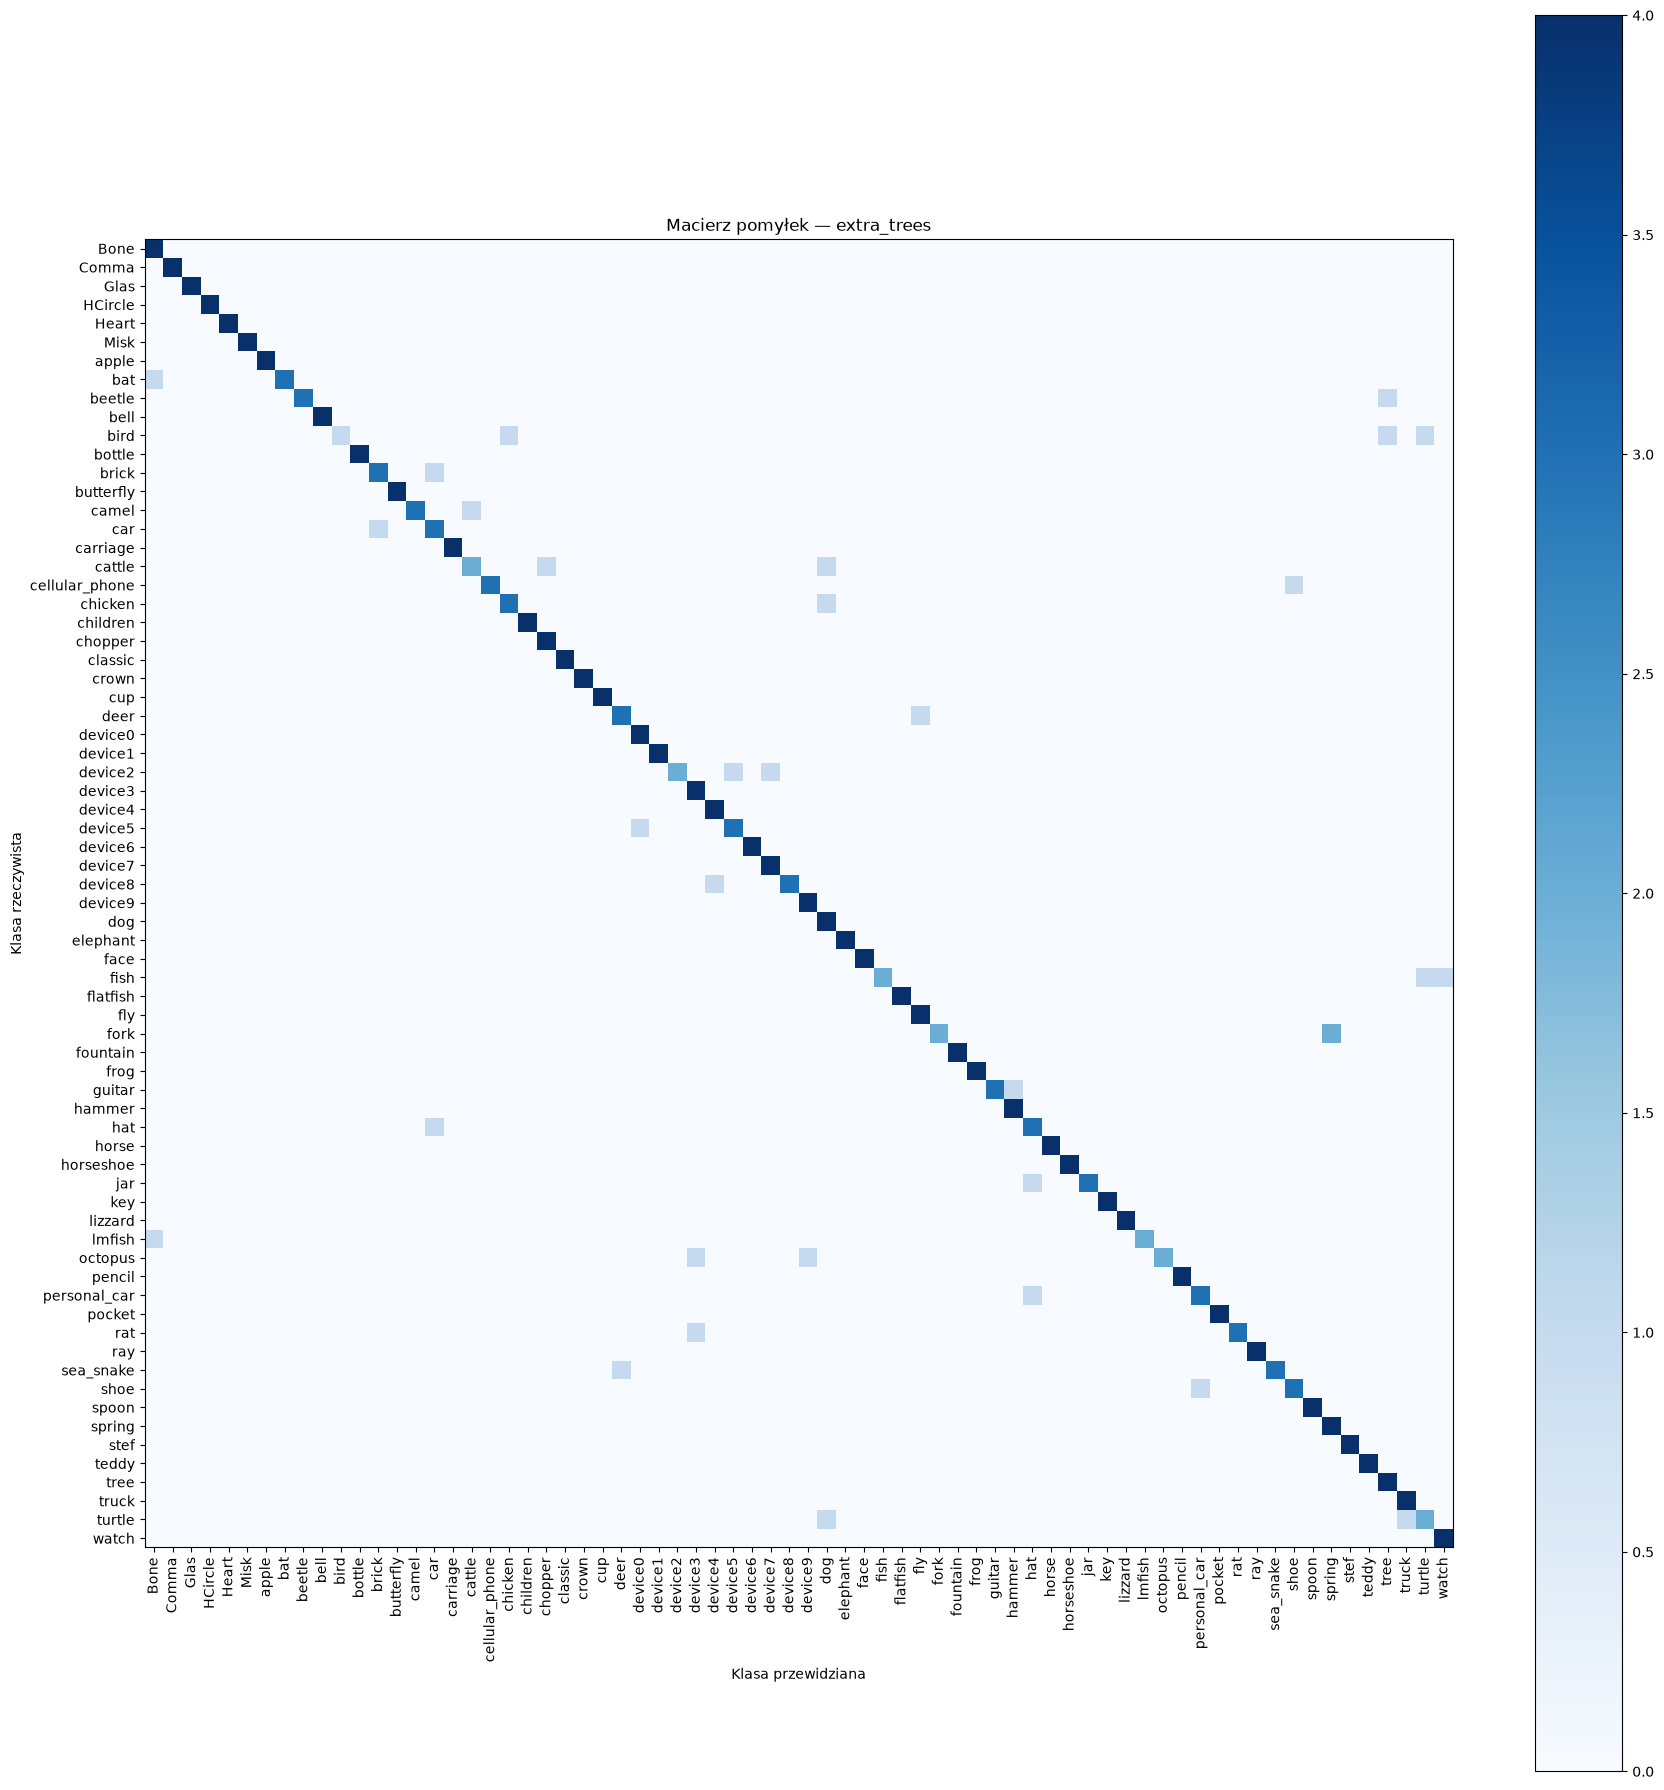

In [96]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
predictions = models[best_model].predict(X_test)

confusion = confusion_matrix(
    Y_test, predictions, labels=models[best_model].classes_
)

fig, ax = plt.subplots(figsize=(18, 18))

ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=models[best_model].classes_,
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    include_values=False,
)

ax.set_title(f"Macierz pomyłek — {best_model}")
ax.set_xlabel("Klasa przewidziana")
ax.set_ylabel("Klasa rzeczywista")

plt.tight_layout()
plt.show()

best model is extra trees with preprocessing models

## Advanced descriptor

### Shape signature and Fourier descriptor

Sygnatura kształtu to odległości punktów konturu od środka ciężkości:
$r(t) = \sqrt{(x(t)-c_x)^2 + (y(t)-c_y)^2}$.
Próbkujemy zamknięty kontur równomiernie po jego długości w 128 punktach.
Następnie liczymy FFT sygnatury i zachowujemy moduły pierwszych 20 współczynników
bez składowej stałej: $f_k = |FFT(r)_k| / |FFT(r)_0|$.

Odległość od centroidu usuwa wpływ przesunięcia i obrotu, moduł FFT usuwa wpływ
cyklicznego przesunięcia początku sygnatury, a dzielenie przez składową stałą
normalizuje skalę. Na obrazach rastrowych niezmienniczość jest przybliżona.
Niskie częstotliwości opisują ogólny kształt, wyższe jego szczegóły.
Sama sygnatura służy tutaj do wyznaczenia deskryptora; do klasyfikacji trafia 20 cech Fouriera.

Źródło: [Shape Retrieval Using Fourier Descriptors](https://users.cs.utah.edu/~tch/CS6640/lectures/Weeks5-6/Zhang.pdf).

In [97]:
def calculate_shape_signature(image_path, n_points=128):
    with Image.open(image_path) as image:
        binary = (np.array(image.convert("L")) > 127).astype(np.uint8) * 255

    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contours:
        raise ValueError(f"Brak obiektu: {image_path}")

    contour = max(contours, key=cv2.contourArea)
    M = cv2.moments(contour)
    if M["m00"] <= 0:
        raise ValueError(f"Zdegenerowany kontur: {image_path}")

    cx = M["m10"] / M["m00"]
    cy = M["m01"] / M["m00"]

    points = contour[:, 0, :].astype(float)
    points = np.vstack([points, points[0]])
    lengths = np.linalg.norm(np.diff(points, axis=0), axis=1)
    distances = np.concatenate([[0], np.cumsum(lengths)])
    sample_distances = np.linspace(0, distances[-1], n_points, endpoint=False)

    x = np.interp(sample_distances, distances, points[:, 0])
    y = np.interp(sample_distances, distances, points[:, 1])
    return np.sqrt((x - cx) ** 2 + (y - cy) ** 2)


def calculate_fourier_features(image_path, n_points=128, n_descriptors=20):
    if not 1 <= n_descriptors <= n_points // 2:
        raise ValueError("Niepoprawna liczba współczynników Fouriera.")

    signature = calculate_shape_signature(image_path, n_points)
    coefficients = np.abs(np.fft.rfft(signature))
    descriptors = coefficients[1:n_descriptors + 1] / coefficients[0]

    return {f"fourier_{i + 1}": value for i, value in enumerate(descriptors)}

In [98]:
# Liczymy cechy od nowa, aby nie korzystać z wcześniej skalowanych danych.
advanced_rows = []

for preprocessing, folder in [("original", original_dir), ("preprocessed", preprocessed_dir)]:
    for dataset_type, dataset in [("train", train_set), ("test", test_set), ("validation", validation_set)]:
        for file in dataset:
            image_path = folder / file
            features = calculate_features(image_path)
            fourier_features = calculate_fourier_features(image_path)

            advanced_rows.append({
                "class": file.split("-")[0],
                "dataset_type": dataset_type,
                "image_path": str(image_path),
                "preprocessing": preprocessing,
                **features,
                **fourier_features,
            })

df_advanced = pd.DataFrame(advanced_rows)
df_advanced.head()

,class,dataset_type,image_path,preprocessing,area,perimeter,diameter,bbox_width,bbox_height,bbox_area,...,fourier_11,fourier_12,fourier_13,fourier_14,fourier_15,fourier_16,fourier_17,fourier_18,fourier_19,fourier_20
0,children,train,original/children-5.gif,original,6275.0,439.847759,167.194702,57,166,9462,...,0.001977,0.001124,0.002622,0.003722,0.002373,0.001379,0.000297,0.001267,0.000415,0.000269
1,children,train,original/children-12.gif,original,6257.5,441.605119,167.529297,59,166,9794,...,0.003444,0.000591,0.002221,0.003109,0.002138,0.001375,0.000669,0.001125,0.000795,0.000973
2,children,train,original/children-6.gif,original,6284.5,440.433546,167.359100,57,166,9462,...,0.001540,0.000785,0.003173,0.003883,0.002547,0.001460,0.000277,0.000730,0.000401,0.001036
3,children,train,original/children-10.gif,original,6278.5,446.918826,167.359100,59,166,9794,...,0.002915,0.000236,0.001811,0.004177,0.001983,0.001447,0.001055,0.000779,0.001094,0.000885
4,children,train,original/children-9.gif,original,6316.5,443.747255,167.705292,59,166,9794,...,0.002621,0.000634,0.002347,0.003772,0.002308,0.001254,0.000914,0.000774,0.000277,0.000662


### Classification comparison

Porównujemy proste cechy, tylko Fouriera oraz połączenie obu zestawów,
z preprocessingiem i bez, na tym samym podziale danych.
Skalowanie dopasowujemy tylko na train. Najlepszy wariant wybieramy według
accuracy na validation; test służy do końcowego porównania.

In [99]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score

fourier_columns = [column for column in df_advanced.columns if column.startswith("fourier_")]
simple_columns = list(calculate_features(original_dir / train_set[0]).keys())

feature_sets = {
    "simple": simple_columns,
    "fourier": fourier_columns,
    "simple + fourier": simple_columns + fourier_columns,
}

# Te same modele i parametry dla każdego wariantu.
advanced_models = {
    "knn 5": KNeighborsClassifier(n_neighbors=5),
    "decision_tree": DecisionTreeClassifier(random_state=42),
    "extra_trees": ExtraTreesClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

advanced_results = []
advanced_fitted_models = {}
advanced_reports = {}
best_advanced_model = None
best_advanced_accuracy = -1

for preprocessing in ["original", "preprocessed"]:
    data = df_advanced[df_advanced["preprocessing"] == preprocessing]
    train = data[data["dataset_type"] == "train"]
    validation = data[data["dataset_type"] == "validation"]

    for feature_name, columns in feature_sets.items():
        for model_name, model in advanced_models.items():
            fitted_model = make_pipeline(StandardScaler(), clone(model))
            fitted_model.fit(train[columns], train["class"])
            predictions = fitted_model.predict(validation[columns])
            accuracy = accuracy_score(validation["class"], predictions)
            key = (preprocessing, feature_name, model_name)
            advanced_fitted_models[key] = fitted_model

            advanced_results.append({
                "preprocessing": preprocessing,
                "features": feature_name,
                "model": model_name,
                "validation_accuracy": accuracy,
                "validation_macro_f1": f1_score(validation["class"], predictions, average="macro", zero_division=0),
            })

            if accuracy > best_advanced_accuracy:
                best_advanced_accuracy = accuracy
                best_advanced_model = fitted_model
                best_advanced_key = key
                best_advanced_columns = columns

            print(f"{key}: validation accuracy = {accuracy:.2%}")

print(f"Best model on validation: {best_advanced_key}")

('original', 'simple', 'knn 5'): validation accuracy = 69.01%
('original', 'simple', 'decision_tree'): validation accuracy = 72.54%
('original', 'simple', 'extra_trees'): validation accuracy = 87.32%
('original', 'fourier', 'knn 5'): validation accuracy = 69.72%
('original', 'fourier', 'decision_tree'): validation accuracy = 66.90%
('original', 'fourier', 'extra_trees'): validation accuracy = 86.62%
('original', 'simple + fourier', 'knn 5'): validation accuracy = 76.76%
('original', 'simple + fourier', 'decision_tree'): validation accuracy = 76.76%
('original', 'simple + fourier', 'extra_trees'): validation accuracy = 93.66%
('preprocessed', 'simple', 'knn 5'): validation accuracy = 76.06%
('preprocessed', 'simple', 'decision_tree'): validation accuracy = 68.31%
('preprocessed', 'simple', 'extra_trees'): validation accuracy = 82.39%
('preprocessed', 'fourier', 'knn 5'): validation accuracy = 73.24%
('preprocessed', 'fourier', 'decision_tree'): validation accuracy = 60.56%
('preprocesse

In [100]:
# Ocena wszystkich ustalonych wariantów; nie wybieramy modelu według testu.
for result in advanced_results:
    key = (result["preprocessing"], result["features"], result["model"])
    test = df_advanced[
        (df_advanced["preprocessing"] == result["preprocessing"])
        & (df_advanced["dataset_type"] == "test")
    ]
    predictions = advanced_fitted_models[key].predict(test[feature_sets[result["features"]]])
    result["test_accuracy"] = accuracy_score(test["class"], predictions)
    result["test_macro_f1"] = f1_score(test["class"], predictions, average="macro", zero_division=0)
    advanced_reports[key] = classification_report(test["class"], predictions, zero_division=0)

df_advanced_results = pd.DataFrame(advanced_results)
df_advanced_results.sort_values("validation_accuracy", ascending=False)

,preprocessing,features,model,validation_accuracy,validation_macro_f1,test_accuracy,test_macro_f1
17,preprocessed,simple + fourier,extra_trees,0.943662,0.926626,0.949821,0.948730
8,original,simple + fourier,extra_trees,0.936620,0.925822,0.939068,0.937506
2,original,simple,extra_trees,0.873239,0.854930,0.842294,0.837687
5,original,fourier,extra_trees,0.866197,0.843897,0.906810,0.901240
14,preprocessed,fourier,extra_trees,0.859155,0.829812,0.870968,0.872673
15,preprocessed,simple + fourier,knn 5,0.830986,0.794366,0.792115,0.789258
11,preprocessed,simple,extra_trees,0.823944,0.794836,0.881720,0.878292
6,original,simple + fourier,knn 5,0.767606,0.731053,0.806452,0.789086
7,original,simple + fourier,decision_tree,0.767606,0.739034,0.716846,0.699225
9,preprocessed,simple,knn 5,0.760563,0.723541,0.763441,0.749675


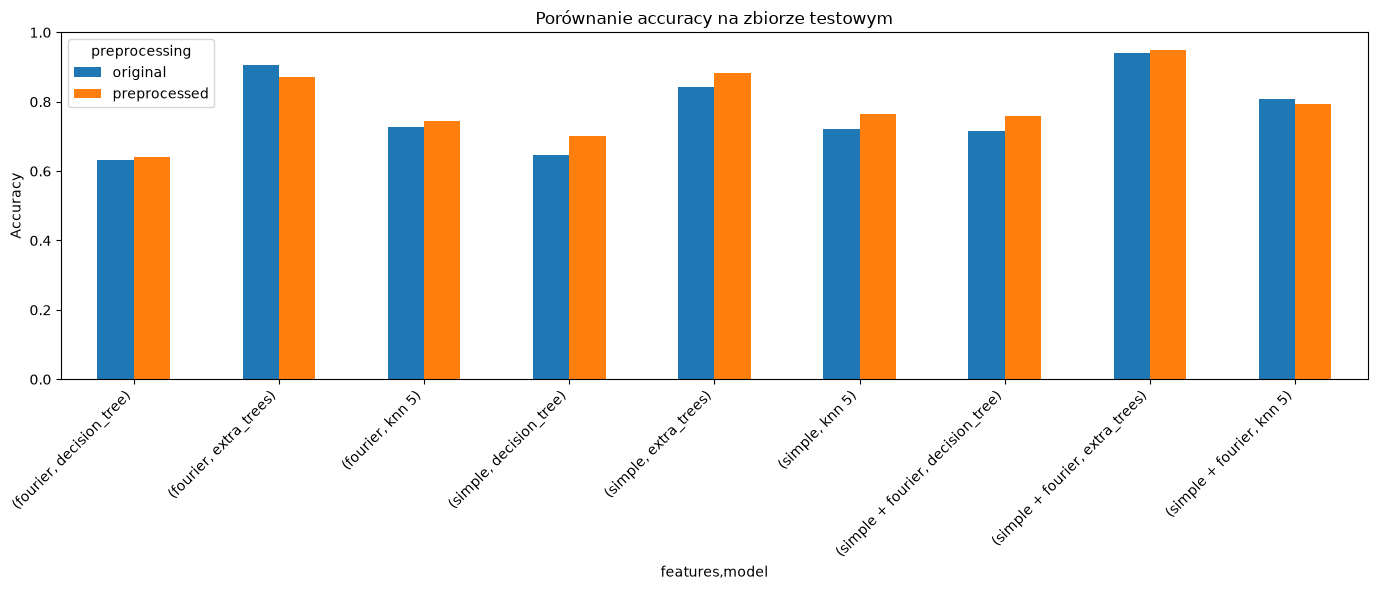

In [101]:
df_advanced_results.pivot(
    index=["features", "model"],
    columns="preprocessing",
    values="test_accuracy",
).plot.bar(figsize=(14, 6))

plt.title("Porównanie accuracy na zbiorze testowym")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()